<a href="https://colab.research.google.com/github/marcia-e/colab_ad05/blob/main/desafios/Desafio2_Estatistica_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Célula 01 - Importações

In [2]:
# ---------- Bibliotecas: ferramentas prontas que o Python usa ----------
import warnings                    # esconde avisos técnicos para não distrair
from pathlib import Path           # manipula caminhos de arquivos e pastas
import shutil                      # manipula arquivos e pastas (ex.: mover, copiar, apagar)

# Estas linhas servem para trabalhar no Google Colab (conectar ao Drive e enviar arquivos)
from google.colab import drive     # conecta o Google Drive ao Colab (para ler e salvar arquivos)
from google.colab import files     # (files) envia arquivos do seu computador para o Colab

# Bibliotecas de análise de dados e de gráficos
import pandas as pd                # tabelas de dados (DataFrame)
import seaborn as sns              # gráficos bonitos e simples
import matplotlib.pyplot as plt    # ajustes nos gráficos (título, linhas...)

# ---------- Configurações gerais (valem para todos os gráficos abaixo) ----------
warnings.filterwarnings("ignore")           # esconde avisos técnicos para não distrair
sns.set_theme(style="whitegrid")            # deixa todos os gráficos com um visual limpo
plt.rcParams["figure.figsize"] = (8, 6)    # tamanho padrão dos gráficos (largura, altura)

### Célula 02 · Carregar os arquivos CSV

In [3]:
# Nomes das tabelas do seu tema (veja a tabela acima), iguais aos nomes dos arquivos CSV.
NOME_TABELA_DIMENSAO = "voos"   # ex.: "livros"
NOME_TABELA_FATO = "reservas"   # ex.: "emprestimos"

# ---------- 1) Conectando ao Google Drive ----------
drive.mount("/content/drive")      # vai pedir autorização na primeira vez

# ---------- 2) Dizendo onde os arquivos estão guardados ----------
pasta_dados = Path("/content/drive/MyDrive/Colab Notebooks/desafios/dados")   # pasta onde a base fica guardada no Drive
pasta_dados.mkdir(parents=True, exist_ok=True)                                # cria a pasta "dados" se faltar

# O "/" junta a pasta com o nome do arquivo (o nome vem da variável de cada tabela).
caminho_dimensao = pasta_dados / f"{NOME_TABELA_DIMENSAO}.csv"
caminho_fato = pasta_dados / f"{NOME_TABELA_FATO}.csv"

# ---------- 3) Se faltar algum arquivo, envia os dois de uma vez e o código separa ----------
if not caminho_dimensao.exists() or not caminho_fato.exists():
    print(f"Selecione os arquivos CSV ({NOME_TABELA_DIMENSAO} e {NOME_TABELA_FATO}). Pode escolher os dois de uma vez:")
    enviados = files.upload()                                  # abre o seletor; aceita vários arquivos

    for nome_enviado in enviados:                              # percorre cada arquivo enviado
        if NOME_TABELA_DIMENSAO in nome_enviado.lower():       # o nome contém o da dimensão? salva como dimensão
            shutil.move(nome_enviado, caminho_dimensao)        # salva já com o nome da tabela
            print(f"{nome_enviado} -> {caminho_dimensao.name}")
        elif NOME_TABELA_FATO in nome_enviado.lower():         # o nome contém o da fato? salva como fato
            shutil.move(nome_enviado, caminho_fato)
            print(f"{nome_enviado} -> {caminho_fato.name}")
        else:                                                  # nome que não combina com nenhuma tabela
            print(f"Ignorado: {nome_enviado} (o nome não contém '{NOME_TABELA_DIMENSAO}' nem '{NOME_TABELA_FATO}')")

# Confere se os dois arquivos estão no Drive antes de ler.
for caminho in [caminho_dimensao, caminho_fato]:
    if not caminho.exists():
        raise FileNotFoundError(f"Falta o arquivo {caminho.name}. Execute a célula de novo e envie-o.")

# ---------- 4) Lendo os dois arquivos ----------
df_dimensao = pd.read_csv(caminho_dimensao)
df_fato = pd.read_csv(caminho_fato)

print(NOME_TABELA_DIMENSAO, "->", len(df_dimensao), "linhas")
print(NOME_TABELA_FATO, "->", len(df_fato), "linhas")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
voos -> 10600 linhas
reservas -> 55000 linhas


### Célula 03 · Conhecendo a tabela dimensão

In [4]:
# Quantas linhas (registros do cadastro) e colunas (variáveis) tem a tabela dimensão?
# .shape devolve dois números: (quantidade de linhas, quantidade de colunas)
linhas, colunas = df_dimensao.shape
print(f"A tabela dimensão tem {linhas} linhas e {colunas} colunas (variáveis)")
display(df_dimensao.head())

A tabela dimensão tem 10600 linhas e 7 colunas (variáveis)


,voo_id,origem,destino,companhia_aerea,data_hora_partida,data_hora_chegada,capacidade_assentos
0,1,João Pessoa,Florianópolis,Voe Fácil,2025-07-28 06:21:29,2025-07-28 10:09:29,220
1,2,Goiânia,Campo Grande,Azul Céu,2025-07-27 15:09:14,2025-07-27 18:31:14,150
2,3,Natal,Vitória,Voe Fácil,2025-06-22 11:02:24,2025-06-22 12:59:24,220
3,4,Porto Alegre,Maceió,LatinWings,2026-08-01 00:21:11,2026-08-01 02:04:11,150
4,5,Brasília,Teresina,Voe Fácil,2026-11-18 15:41:18,2026-11-18 20:26:18,150


### Célula 04 · Conhecendo a tabela fato

In [5]:
# Quantas linhas (eventos) e colunas (variáveis) tem a tabela fato?
# .shape devolve dois números: (quantidade de linhas, quantidade de colunas)
linhas, colunas = df_fato.shape
print(f"A tabela fato tem {linhas} linhas e {colunas} colunas (variáveis)")
display(df_fato.head())

A tabela fato tem 55000 linhas e 8 colunas (variáveis)


,reserva_id,voo_id,passageiro_id,data_compra,classe,valor_pago,forma_pagamento,status
0,1,595,61723,2026-09-11,economica,432.66,cartao_debito,confirmada
1,2,8943,77693,2026-11-16,executiva,1538.60,pix,confirmada
2,3,8487,76139,2026-01-19,economica,625.07,pix,confirmada
3,4,6454,59514,2026-06-26,economica,344.06,cartao_credito,cancelada
4,5,8521,44964,2025-11-07,economica,347.23,cartao_debito,confirmada


### Pergunta que eu quero responder:
"Os valores das passagens aéreas são parecidos entre as reservas ou varia muito entre as classes?"

### Célula 05 · Tipos das colunas

In [6]:
# 1) Tipo de cada coluna e quantidade de valores preenchidos. Compare com o esquema do plano do tema.
df_fato.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 55000 entries, 0 to 54999
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   reserva_id       55000 non-null  int64  
 1   voo_id           55000 non-null  int64  
 2   passageiro_id    55000 non-null  int64  
 3   data_compra      55000 non-null  object 
 4   classe           55000 non-null  object 
 5   valor_pago       55000 non-null  float64
 6   forma_pagamento  55000 non-null  object 
 7   status           55000 non-null  object 
dtypes: float64(1), int64(3), object(4)
memory usage: 3.4+ MB


### Célula 06 · Valores ausentes

In [7]:
# 2) Valores ausentes por coluna (tabela fato).
print("\nValores ausentes por coluna:")
print(df_fato.isna().sum())


Valores ausentes por coluna:
reserva_id         0
voo_id             0
passageiro_id      0
data_compra        0
classe             0
valor_pago         0
forma_pagamento    0
status             0
dtype: int64


### Célula 07 · Linhas duplicadas

In [8]:
# 3) Linhas duplicadas (tabela fato).
print("\nLinhas duplicadas:", df_fato.duplicated().sum())


Linhas duplicadas: 0


### Célula 08 · Chave estrangeira

In [9]:
# 4) Chave estrangeira: todos os registros da tabela fato devem apontar para um ID que existe na tabela dimensão.
COLUNA_FK = "voo_id"        # ex.: "livro_id" (coluna da fato que referencia a dimensão)
COLUNA_ID = "voo_id"   # ex.: "livro_id" (coluna de ID da dimensão)
print("\nChaves estrangeiras que batem:", df_fato[COLUNA_FK].isin(df_dimensao[COLUNA_ID]).all())


Chaves estrangeiras que batem: True


### Célula 09 · Checar a coluna numérica

In [10]:
# Coluna numérica escolhida no Passo 1 (nome EXATO, como está no esquema do tema).
COLUNA_NUMERICA = "valor_pago"

# A coluna escolhida, como uma série (uma coluna do DataFrame).
serie_numerica = df_fato[COLUNA_NUMERICA]
print("Valores preenchidos:", serie_numerica.count(), "| ausentes:", serie_numerica.isna().sum())

Valores preenchidos: 55000 | ausentes: 0


### Célula 10 · Medidas estatísticas

In [11]:
# Medidas de Tendência central e dispersão.
medidas = pd.Series({
    "Média": serie_numerica.mean(),
    "Mediana": serie_numerica.median(),
    "Moda": serie_numerica.mode()[0],            # se houver empate, a primeira será selecionada
    "Desvio padrão": serie_numerica.std(),
    "Variância": serie_numerica.var(),
    "Mínimo": serie_numerica.min(),
    "Máximo": serie_numerica.max(),
    "Amplitude": serie_numerica.max() - serie_numerica.min(),
}).round(2)
display(medidas)

# Média muito diferente da mediana é sinal de valores extremos ou de dados assimétricos.
print("Média - mediana:", round(medidas["Média"] - medidas["Mediana"], 2))

,0
Média,888.86
Mediana,599.56
Moda,310.35
Desvio padrão,906.16
Variância,821124.79
Mínimo,181.34
Máximo,5998.20
Amplitude,5816.86


Média - mediana: 289.3


### Insights

Inicialmente foram analisados os valores totais pagos pelas 55.000 reservas, sem separação por classe e foi possível concluir que:

- A **média dos valores totais pagos é de R$888,86**, representando o valor médio das passagens considerando todas as reservas. Contudo, esse resultado é superior à mediana (demonstradas logo abaixo), indicando que os pagamentos mais elevados influenciam o valor médio geral.

- A **mediana desses valores é de R$599,56**, indicando que metades das reservas apresenta valores iguais ou inferiores a esse montante, enquanto a outra metade apresenta valores iguais ou superiores. Há uma diferença de R\$289,30 reais em relação à média, reforçando a influência dos valores mais altos sobre a média.

- **O desvio padrão é de R$906,16**, o que demonstra indicando diferenças consideráveis entre as reservas.

- **Decisão final:** os valores pagos apresentam grande variação, e a média geral, isoladamente, não representa adequadamente o valor típico das passagens.

### Célula 11 · Juntar a fato com a dimensão (JOIN)

In [12]:
# Junta a fato com a dimensão: cada registro da fato recebe as colunas do seu cadastro.
df_completo = df_fato.merge(df_dimensao, left_on=COLUNA_FK, right_on=COLUNA_ID, how="left", suffixes=("", "_dim")) ## recomendado manter esquerda a tabela que tem mais linhas

print("Linhas da fato:", len(df_fato), "| depois da junção:", len(df_completo))   # precisam ser iguais

Linhas da fato: 55000 | depois da junção: 55000


In [13]:
df_completo.head()

,reserva_id,voo_id,passageiro_id,data_compra,classe,valor_pago,forma_pagamento,status,origem,destino,companhia_aerea,data_hora_partida,data_hora_chegada,capacidade_assentos
0,1,595,61723,2026-09-11,economica,432.66,cartao_debito,confirmada,Belém,Rio de Janeiro,LatinWings,2026-09-17 22:00:41,2026-09-17 23:10:41,220
1,2,8943,77693,2026-11-16,executiva,1538.60,pix,confirmada,Rio de Janeiro,São Paulo,TransBrasil Air,2026-11-26 22:49:08,2026-11-27 01:12:08,120
2,3,8487,76139,2026-01-19,economica,625.07,pix,confirmada,Vitória,Cuiabá,Azul Céu,2026-02-17 05:15:13,2026-02-17 07:52:13,150
3,4,6454,59514,2026-06-26,economica,344.06,cartao_credito,cancelada,Brasília,Belém,Azul Céu,2026-07-14 19:16:47,2026-07-14 23:00:47,150
4,5,8521,44964,2025-11-07,economica,347.23,cartao_debito,confirmada,Recife,Florianópolis,Azul Céu,2025-12-09 15:41:48,2025-12-09 18:05:48,120


### Célula 12 · Comparar grupos por uma coluna da fato

In [14]:
# Coluna categórica usada para comparar (da fato ou da dimensão). Poucos valores diferentes funcionam melhor.
COLUNA_GRUPO = "classe"

# Quantidade, média, mediana e desvio padrão de cada grupo, do maior para o menor valor médio.
por_grupo = df_completo.groupby(COLUNA_GRUPO)[COLUNA_NUMERICA].agg(["count", "mean", "median", "std"]).round(2)
por_grupo = por_grupo.sort_values("mean", ascending=False)
display(por_grupo)

,count,mean,median,std
classe,,,,
executiva,5533,3224.44,3197.46,1021.28
premium,10941,1144.84,1134.17,299.92
economica,38526,480.74,477.66,168.29


### **Leitura por classes**

Ao separar as reservas por classe, foi possível identificas diferenças expressivas nos valores pagos.

- A **classe executiva** apresenta a maior média, de R\$3.224,44, seguida pela
premium, com R\$1.144,84, e pela econômica, com R$480,74.

- As **medianas** acompanham esse comportamento, apresentado valores de R\$3.197,46, R\$1.134,17 e R\$480,74, respectivamente. A proximidade entre a média e a mediana de cada classe indica que os valores centrais são relativamente próximos, quando comparados à distribuição geral.

- Em relação ao **desvio padrão**, a classe executiva apresenta o maior número (R\$1.021,28), seguido pela premium (R\$299,92) e pela econômica (R\$168,29), o que demontra uma maior variação.

- Outro ponto importante é a quantidade de reservas: a classe econômica concentra 38,526 reservas, sendo aproximadamente 70% da base, enquanto a executiva representa 5.533 registros (aproximadamente 10%).

**Decisão final:** os valores das passagens variam significativamente entre as classes. A executiva apresenta os maiores preços enquanto a econônica concentra a maior quantidade de reservas e menores valores.

###Célula 13 · Comparar grupos por uma coluna da dimensão

In [20]:
COLUNA_GRUPO = "classe"     # coluna da dimensão: só existe em df_completo por causa da junção

# Quantidade, média, mediana e desvio padrão de cada grupo, do maior para o menor valor médio.
por_grupo = df_completo.groupby(COLUNA_GRUPO)[COLUNA_NUMERICA].agg(["count", "mean", "median", "std"]).round(2)
por_grupo = por_grupo.sort_values("mean", ascending=False)
display(por_grupo)

,count,mean,median,std
classe,,,,
executiva,5533,3224.44,3197.46,1021.28
premium,10941,1144.84,1134.17,299.92
economica,38526,480.74,477.66,168.29


### Célula 14 · Regra do IQR

In [21]:
# Faixa central dos dados: do 1º ao 3º quartil (25% e 75%).
q1 = serie_numerica.quantile(0.25)
q3 = serie_numerica.quantile(0.75)
iqr = q3 - q1

# Regra usual: fora de [Q1 - 1,5 x IQR ; Q3 + 1,5 x IQR] é candidato a outlier.
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

# Cálculo do número de outliers
sem_outliers = serie_numerica[(serie_numerica >= limite_inferior) & (serie_numerica <= limite_superior)]
qtd_outliers = serie_numerica.count() - sem_outliers.count()

print(f"Limites: {limite_inferior:.2f} a {limite_superior:.2f}")
print(f"Outliers: {qtd_outliers} de {serie_numerica.count()} valores")
print("Maiores valores:", serie_numerica.nlargest(5).tolist())
print("Menores valores:", serie_numerica.nsmallest(5).tolist())

Limites: -358.53 a 1657.26
Outliers: 5713 de 55000 valores
Maiores valores: [5998.2, 5960.11, 5935.49, 5917.95, 5903.23]
Menores valores: [181.34, 181.97, 182.61, 182.9, 183.02]


### Célula 15 · Medidas com e sem os candidatos a outlier

In [22]:
# Compara as medidas com e sem os candidatos a outlier.
comparacao = pd.DataFrame({
    "Com outliers": [serie_numerica.mean(), serie_numerica.median(), serie_numerica.std()],
    "Sem outliers": [sem_outliers.mean(), sem_outliers.median(), sem_outliers.std()],
}, index=["Média", "Mediana", "Desvio padrão"]).round(2)
display(comparacao)

,Com outliers,Sem outliers
Média,888.86,622.44
Mediana,599.56,557.17
Desvio padrão,906.16,333.76


###Leitura e decisão registrada


- A partir da leitura da **regra do IQR**, foi possível identificar 5.713 outliers da quantia total e os limites superior e inferior ficaram entre R\$1.657,26 e R\$-358,53, respectivamente.
- Ao comparar as medidas **desconsiderando os outliers**, é possível notar uma redução significativa da **média**, que passou de R\$888,86 para R\$622,44. O **desvio padrão** também apresentou uma redução significativa, passando de R\$906,16 para R\$333,76.
- Esses resultados demonstram que os valores extremos exercem uma influência considerável sobre a média e o desvio padrão geral dos preços, enquanto a mediana sofre menos impacto.
- **Decisão:** optou-se por manter os candidatos a outliers na análise principal, considerando que os valores elevados representam pagamentos legítimos, especialmente nas classes superiores.
- **Valores ausentes:** não foi identificados valores ausentes na presente base de dados, portanto, não foi necessário realizar nenhum procedimento de preenchimento ou exclusão de registros.

###Célula 16 · Assimetria (skew)

In [23]:
# Assimetria: perto de 0 = formato equilibrado; positiva = cauda para valores altos; negativa = para valores baixos.
print("Assimetria:", round(serie_numerica.skew(), 2))

Assimetria: 2.66


###Célula 17 · Percentis

In [41]:
# Percentis: por exemplo, 50% dos valores ficam na mediana ou abaixo dela.
print(serie_numerica.quantile([0.10, 0.25, 0.50, 0.75, 0.90]))

0.10     277.0990
0.25     397.3900
0.50     599.5600
0.75     901.3375
0.90    1708.3450
Name: valor_pago, dtype: float64


###Célula 18 · Quantidade de valores por faixa

In [25]:
# Quantidade de valores em 5 faixas de mesmo tamanho (a versão em texto de um histograma).
display(pd.cut(serie_numerica, bins=5).value_counts().sort_index())

,count
valor_pago,
"(175.523, 1344.712]",46251
"(1344.712, 2508.084]",4852
"(2508.084, 3671.456]",1861
"(3671.456, 4834.828]",1769
"(4834.828, 5998.2]",267


**Leitura da distribuição**

- A **análise da assimetria** apresentou um resultado de 2,66, indicando uma distribuição assimétrica à direita (cauda prologanda à direita visto no histrograma do bloco 19). Isso indica que os valores das reservas se concentram em valores mais baixos, enquanto uma quantidade menor apresentam valores elevados.
- Os **percentis** reforçam esse diagnótico: 75% das reservas apresentam valores de até R\$901,34 enquanto 90% dos registros vão até R\$1.708,35.
- Na análise da quantidade de **registros por faixa**, observou-se que 46.251 reservas estão concentradas no primeiro intervalo de valores, entre R\$175,52 e R\$1.344,71. Nas faixas seguintes a quantidade de registros diminuem consideravalmente.

**Decisão final:** a distribuição demonstra uma forte concentração de reservas em valores inferiores, enquanto uma parcela menor apresenta preços significativamente mais elevados, reforçando a influência desses registros sobre a média geral.



## Recomendação

**Pergunta de negócio:** *"Os valores das passagens aéreas são parecidos entre as reservas ou varia muito entre as classes?"*

**Evidência 1:** a média da classe executiva é de **R\$3.224,44**, enquanto a classe econômica apresenta média de **R\$480,74**. A diferença de **R\$2.743,70** demonstra que os valores pagos variam significativamente conforme a classe. As medianas também confirmam essa diferença, indicando que não se trata apenas da influência de alguns pagamentos extremos.

**Evidência 2:** a **retirada dos candidatos a outliers** reduziu a média geral de R\$888,86 para R\$622,44 e o desvio padrão de R\$906,16 para R\$333,76. Isso demonstra que os pagamentos mais elevados influenciam consideravelmente os resultados gerais e reforça a importância de analisar os preços considerando suas diferentes categorias.

**Recomendação em uma frase:** os valores das passagens variam significativamente entre as classes. Portanto, recomenda-se analisar e acompanhar os preços separadamente por categoria, evitando utilizar somente a média geral como referência para avaliar os valores das reservas.

**Limites da análise:** os dados são fictícios. optou-se por manter os candidatos a outliers na análise principal, considerando que os valores elevados representam pagamentos legítimos, especialmente nas classes superiores.Os candidatos a outliers foram mantidos por não haver evidência de que sejam erros ou inconsistências.

###Célula 19 · Histograma

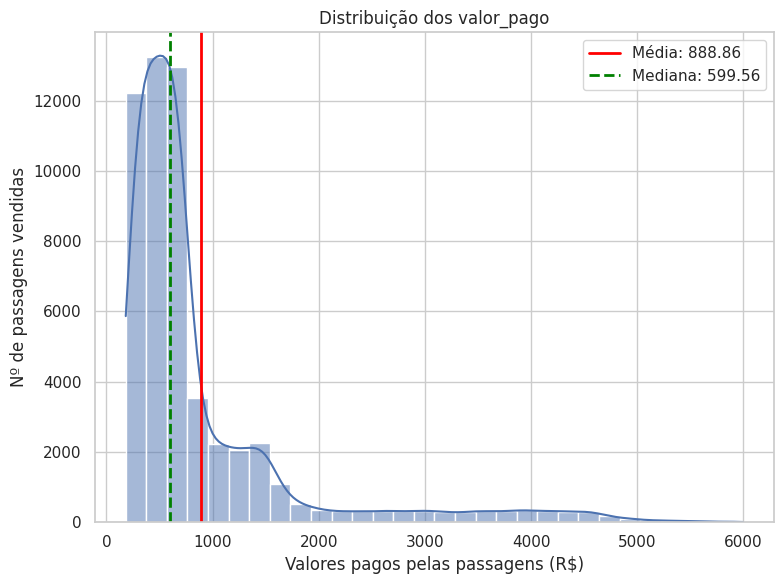

In [35]:
# Histograma: como os valores se distribuem, com a curva da distribuição e as linhas de média e mediana.
sns.histplot(serie_numerica.dropna(), bins=30, kde=True)
plt.axvline(serie_numerica.mean(), color="red", linestyle="-", linewidth=2, label=f"Média: {serie_numerica.mean():.2f}")
plt.axvline(serie_numerica.median(), color="green", linestyle="--", linewidth=2, label=f"Mediana: {serie_numerica.median():.2f}")
plt.title(f"Distribuição dos {COLUNA_NUMERICA}")
plt.xlabel("Valores pagos pelas passagens (R$)")        # lacuna: nome do eixo x, em linguagem simples
plt.ylabel("Nº de passagens vendidas")            # lacuna: nome do eixo y, em linguagem simples
plt.legend()
plt.tight_layout()
plt.show()

###Célula 20 · Boxplot

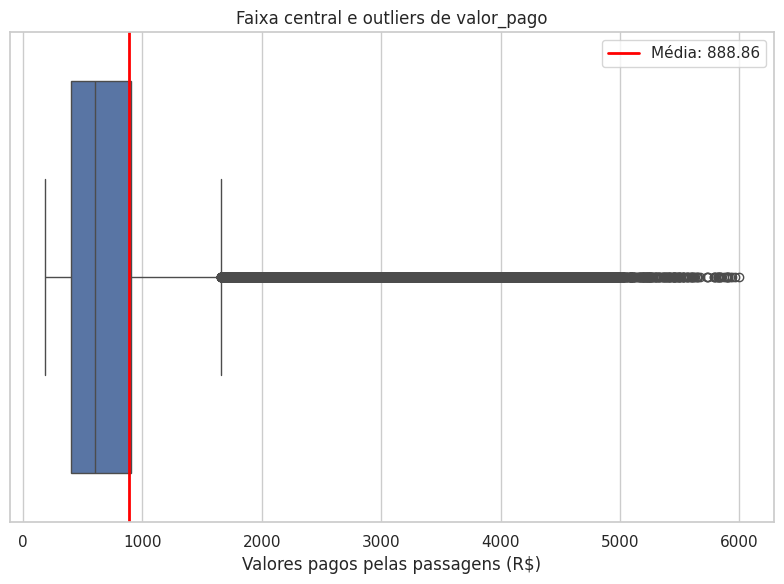

In [43]:
# Boxplot: a caixa é a faixa central (25% a 75%); os pontos fora são candidatos a outlier.
sns.boxplot(x=serie_numerica.dropna())
plt.axvline(serie_numerica.mean(), color="red", linestyle="-", linewidth=2, label=f"Média: {serie_numerica.mean():.2f}")
plt.title(f"Faixa central e outliers de {COLUNA_NUMERICA}")
plt.xlabel("Valores pagos pelas passagens (R$)")        # lacuna: nome do eixo x, em linguagem simples
plt.legend()
plt.tight_layout()
plt.show()